In [1]:
!pip install opencv-python numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl (12.6 MB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 322.4 kB/s eta 0:00:28
   -- ----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import cv2

image = cv2.imread(
    r'C:\Users\acer\OneDrive\Pictures\Camera Roll\road.jpg'
)

if image is None:
    print("Error: Image not found!")
else:
    print("Image loaded successfully!")
    print("Image dimensions:", image.shape)

Image loaded successfully!
Image dimensions: (941, 1672, 3)


In [5]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [6]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Grayscale conversion completed!")

Grayscale conversion completed!


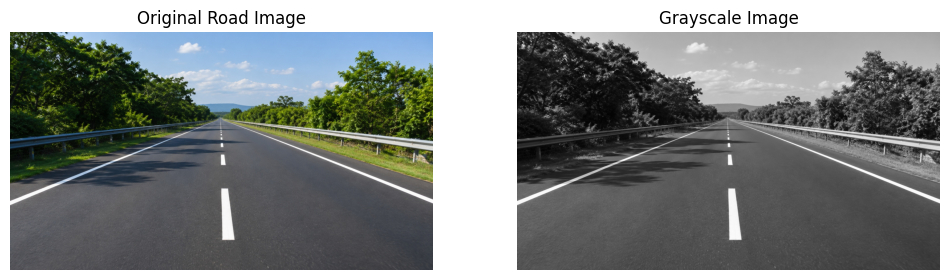

In [7]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Road Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

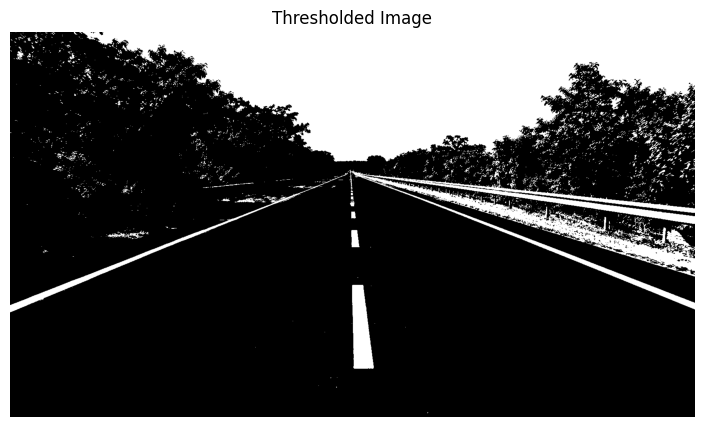

In [8]:
threshold = 127

ret, binary = cv2.threshold(
    gray,
    threshold,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(10,5))
plt.imshow(binary, cmap='gray')
plt.title("Thresholded Image")
plt.axis("off")
plt.show()

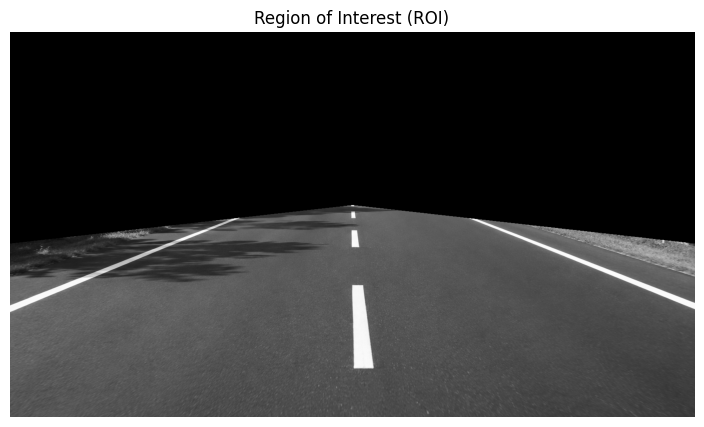

In [11]:
height, width = gray.shape

mask = np.zeros_like(gray)

polygon = np.array([[
    (0, height),
    (width, height),
    (width, int(height * 0.55)),
    (int(width * 0.5), int(height * 0.45)),
    (0, int(height * 0.55))
]], dtype=np.int32)

cv2.fillPoly(mask, polygon, 255)

masked_image = cv2.bitwise_and(gray, mask)

plt.figure(figsize=(12,5))
plt.imshow(masked_image, cmap='gray')
plt.title("Region of Interest (ROI)")
plt.axis("off")
plt.show()

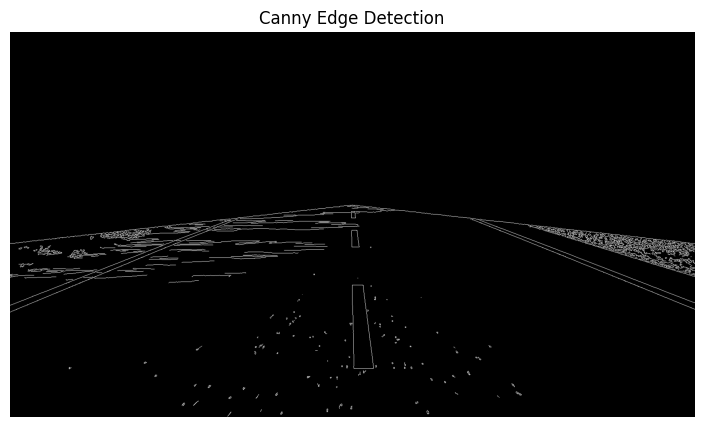

In [12]:
edges = cv2.Canny(masked_image, 50, 150)

plt.figure(figsize=(12,5))
plt.imshow(edges, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()

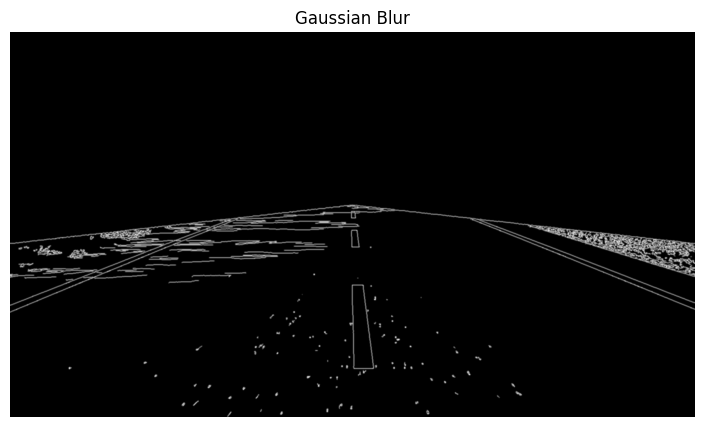

In [13]:
blurred = cv2.GaussianBlur(edges, (5,5), 0)

plt.figure(figsize=(12,5))
plt.imshow(blurred, cmap='gray')
plt.title("Gaussian Blur")
plt.axis("off")
plt.show()

In [14]:
lines = cv2.HoughLinesP(
    blurred,
    rho=1,
    theta=np.pi/180,
    threshold=50,
    minLineLength=50,
    maxLineGap=100
)

print("Detected lines:", 0 if lines is None else len(lines))

Detected lines: 330


In [16]:
left_lines = []
right_lines = []

height, width = image.shape[:2]

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = np.array(line).flatten()

        if x2 == x1:
            continue

        slope = (y2 - y1) / (x2 - x1)

        if -1.5 < slope < -0.3 and (x1 + x2) / 2 < width / 2:
            left_lines.append((x1, y1, x2, y2))

        elif 0.3 < slope < 1.5 and (x1 + x2) / 2 > width / 2:
            right_lines.append((x1, y1, x2, y2))

print("Left lane segments:", len(left_lines))
print("Right lane segments:", len(right_lines))

Left lane segments: 19
Right lane segments: 50


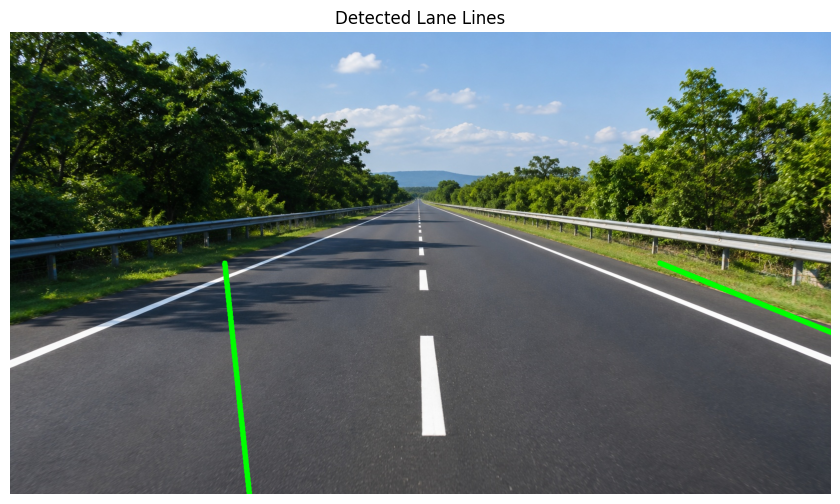

In [17]:
lane_image = image.copy()

def draw_lane(line_segments, color=(0, 255, 0)):
    if len(line_segments) == 0:
        return

    points = []

    for x1, y1, x2, y2 in line_segments:
        points.append((x1, y1))
        points.append((x2, y2))

    points = np.array(points)

    # Fit x as a function of y
    fit = np.polyfit(points[:, 1], points[:, 0], 1)

    y_bottom = height - 1
    y_top = int(height * 0.50)

    x_bottom = int(np.polyval(fit, y_bottom))
    x_top = int(np.polyval(fit, y_top))

    cv2.line(
        lane_image,
        (x_bottom, y_bottom),
        (x_top, y_top),
        color,
        10
    )

draw_lane(left_lines)
draw_lane(right_lines)

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(lane_image, cv2.COLOR_BGR2RGB))
plt.title("Detected Lane Lines")
plt.axis("off")
plt.show()

In [18]:
cv2.imwrite("lane_detection_output.jpg", lane_image)

print("Final lane detection image saved successfully!")

Final lane detection image saved successfully!


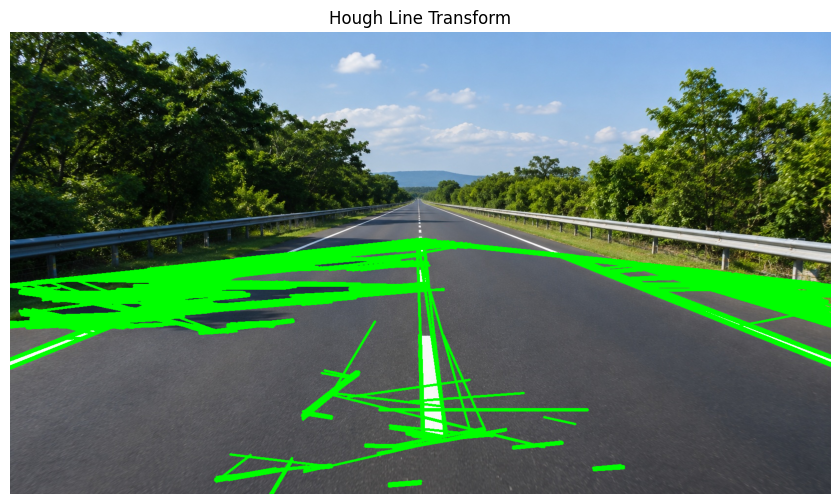

In [19]:
hough_image = image.copy()

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = np.array(line).flatten()

        cv2.line(
            hough_image,
            (int(x1), int(y1)),
            (int(x2), int(y2)),
            (0, 255, 0),
            3
        )

plt.figure(figsize=(12, 6))

plt.imshow(cv2.cvtColor(hough_image, cv2.COLOR_BGR2RGB))
plt.title("Hough Line Transform")
plt.axis("off")

plt.show()